In [1]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("week6_graph_edges.csv")

df.head()

,Source,Target,Weight
0,A,B,5
1,A,C,4
2,A,D,3
3,B,C,5
4,B,D,4


In [3]:
print("Number of rows:", len(df))
print(df.info())

Number of rows: 50
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Source  50 non-null     object
 1   Target  50 non-null     object
 2   Weight  50 non-null     int64 
dtypes: int64(1), object(2)
memory usage: 1.3+ KB
None


In [4]:
G = nx.from_pandas_edgelist(
    df,
    source="Source",
    target="Target",
    edge_attr="Weight"
)

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Number of nodes: 24
Number of edges: 50


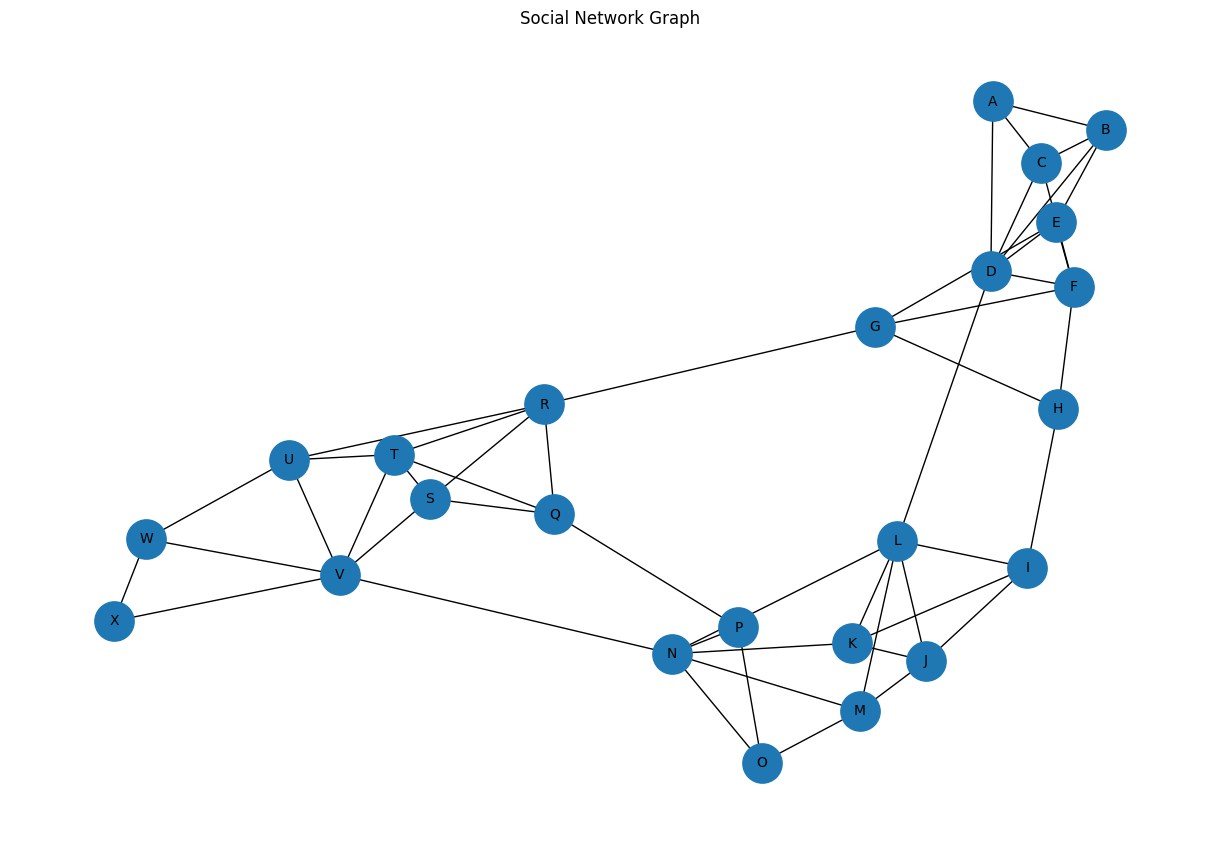

In [5]:
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=800,
    font_size=10
)

plt.title("Social Network Graph")
plt.show()

In [6]:
bfs = list(nx.bfs_tree(G, source="A"))

print("BFS Traversal:")
print(bfs)

BFS Traversal:
['A', 'B', 'C', 'D', 'E', 'F', 'L', 'G', 'H', 'I', 'J', 'K', 'M', 'N', 'R', 'O', 'P', 'V', 'Q', 'S', 'T', 'U', 'W', 'X']


In [7]:
dfs = list(nx.dfs_preorder_nodes(G, source="A"))

print("DFS Traversal:")
print(dfs)

DFS Traversal:
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X']


In [8]:
degree_centrality = nx.degree_centrality(G)

degree_df = pd.DataFrame(
    degree_centrality.items(),
    columns=["Node", "Degree Centrality"]
)

degree_df = degree_df.sort_values(
    by="Degree Centrality",
    ascending=False
)

degree_df

,Node,Degree Centrality
3,D,0.260870
21,V,0.260870
13,N,0.260870
11,L,0.260870
17,R,0.217391
5,F,0.217391
19,T,0.217391
2,C,0.173913
18,S,0.173913
20,U,0.173913


In [9]:
betweenness = nx.betweenness_centrality(G)

betweenness_df = pd.DataFrame(
    betweenness.items(),
    columns=["Node", "Betweenness Centrality"]
)

betweenness_df = betweenness_df.sort_values(
    by="Betweenness Centrality",
    ascending=False
)

betweenness_df

,Node,Betweenness Centrality
13,N,0.292245
11,L,0.249769
21,V,0.223137
3,D,0.206531
17,R,0.188999
6,G,0.188189
5,F,0.069965
4,E,0.051849
8,I,0.050696
20,U,0.045130


In [10]:
closeness = nx.closeness_centrality(G)

closeness_df = pd.DataFrame(
    closeness.items(),
    columns=["Node", "Closeness Centrality"]
)

closeness_df = closeness_df.sort_values(
    by="Closeness Centrality",
    ascending=False
)

closeness_df

,Node,Closeness Centrality
13,N,0.469388
11,L,0.469388
3,D,0.410714
10,K,0.410714
21,V,0.410714
6,G,0.403509
12,M,0.396552
17,R,0.396552
5,F,0.383333
19,T,0.377049


In [11]:
results = pd.DataFrame({
    "Node": list(G.nodes()),
    "Degree Centrality": [
        degree_centrality[node] for node in G.nodes()
    ],
    "Betweenness Centrality": [
        betweenness[node] for node in G.nodes()
    ],
    "Closeness Centrality": [
        closeness[node] for node in G.nodes()
    ]
})

results = results.sort_values(
    by="Betweenness Centrality",
    ascending=False
)

results

,Node,Degree Centrality,Betweenness Centrality,Closeness Centrality
13,N,0.260870,0.292245,0.469388
11,L,0.260870,0.249769,0.469388
21,V,0.260870,0.223137,0.410714
3,D,0.260870,0.206531,0.410714
17,R,0.217391,0.188999,0.396552
6,G,0.173913,0.188189,0.403509
5,F,0.217391,0.069965,0.383333
4,E,0.173913,0.051849,0.370968
8,I,0.173913,0.050696,0.370968
20,U,0.173913,0.045130,0.365079


In [12]:
from networkx.algorithms.community import greedy_modularity_communities

communities = list(
    greedy_modularity_communities(G)
)

for i, community in enumerate(communities, start=1):
    print(f"Community {i}: {sorted(community)}")

Community 1: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']
Community 2: ['I', 'J', 'K', 'L', 'M', 'N', 'O', 'P']
Community 3: ['Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X']


In [13]:
community_map = {}

for i, community in enumerate(communities):
    for node in community:
        community_map[node] = i

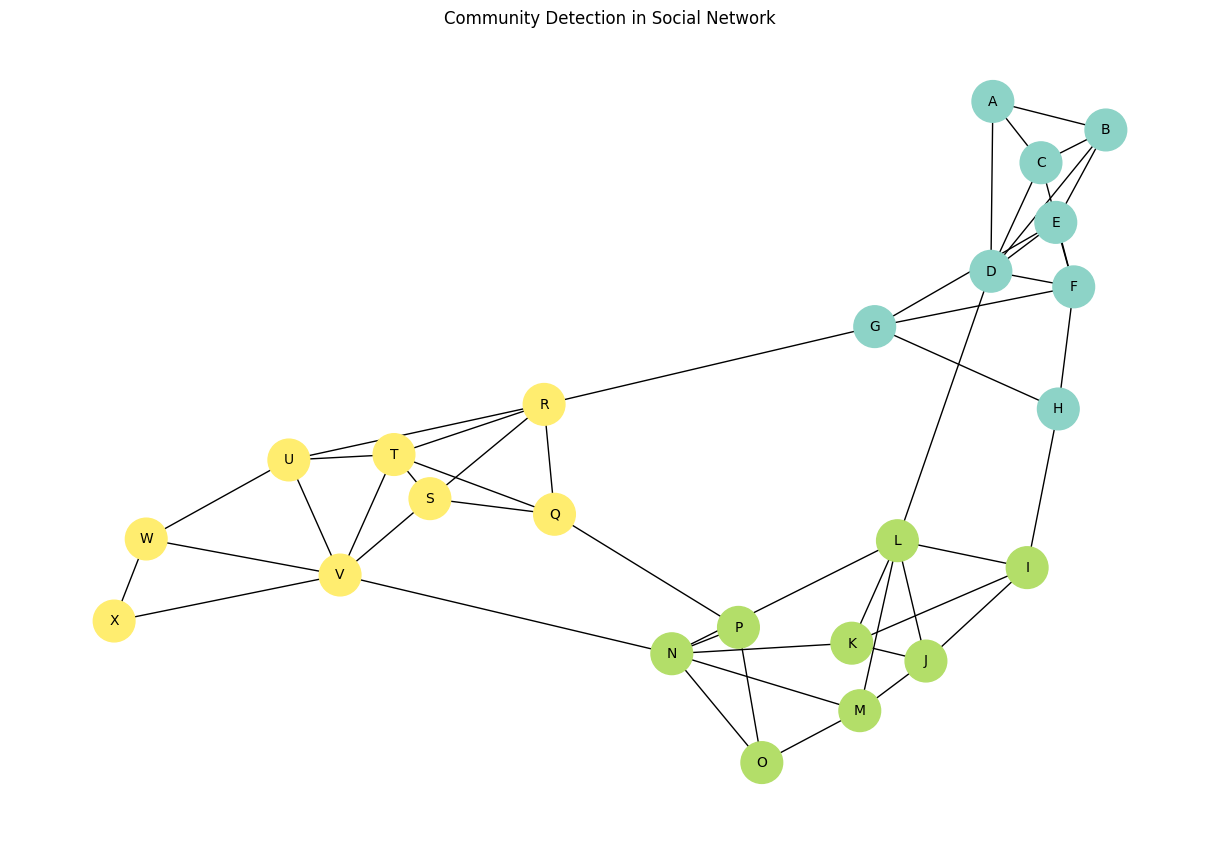

In [14]:
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G, seed=42)

node_colors = [
    community_map[node]
    for node in G.nodes()
]

nx.draw(
    G,
    pos,
    with_labels=True,
    node_color=node_colors,
    cmap=plt.cm.Set3,
    node_size=900,
    font_size=10
)

plt.title("Community Detection in Social Network")
plt.show()

In [15]:
most_influential = max(
    degree_centrality,
    key=degree_centrality.get
)

print("Most influential node based on degree centrality:")
print(most_influential)

print(
    "Degree Centrality:",
    degree_centrality[most_influential]
)

Most influential node based on degree centrality:
D
Degree Centrality: 0.2608695652173913


In [16]:
for i, community in enumerate(communities, start=1):

    community_degree = {
        node: degree_centrality[node]
        for node in community
    }

    most_important = max(
        community_degree,
        key=community_degree.get
    )

    print(
        f"Community {i} most influential node:",
        most_important
    )

Community 1 most influential node: D
Community 2 most influential node: N
Community 3 most influential node: V


# Conclusion

In this practical analysis, NetworkX was used to create and analyze a hypothetical social network. BFS and DFS demonstrated how graph traversal methods explore connected nodes. Centrality measures identified nodes that were highly connected or acted as important bridges within the network. Community detection grouped closely connected nodes into separate communities. The results show how graph analytics can help identify influential entities and hidden structures in large interconnected datasets.